# Space-charge QA on the v7 scan: every current difference, every map (2026-10-22)
**Question.** dφ vs R has an **arch in R1** (30–40.5 cm), strong in South, and growing at high luminosity on both sides.
Is it space charge (it then grows with I_GEM and a map with the right inner shape removes it) or static / geometry (the
same in every run, or changing between periods independently of the current)?

**Data.** v7 scan: the joint static (South IFC −36 / OFC −17 V / frames −110, North −138 / −41 V / −165, vs automatic)
with the m = 120 frame maps, on all 17 beam blocks (795xx: I 1.8–2.8 µA, 80892 / 81558: 5.4–7.0 µA):
- `static only` (no space-charge correction): what is left is the data's space charge + static residual. **Differences
  between runs or blocks of `static only` = the measured space-charge change** (the static is the same correction in every
  run, so it cancels, as far as the real static is the same).
- `map m at b`: α 1.8 × kink 22.75 / 23.9 / 25 / 26.25 / 27.5, α 1.6 × 23.9 / 25 / 26.25, α 1.7 × 25; b 0.40 … 0.75.
  Differences of these = what the correction **leaves** of the change.
- the current CDB (its own static + α 1.8 at keff = 1.55 (0.815 I/I₇₉₅₁₃ + 0.185)).

**Every profile** is dφ [mrad] (30–32 cm: inner-edge matching unreliable at high current, grey band, excluded from all numbers) vs R, K0s-weighted φ average vs the fully aligned truth, sector edges excluded, **nothing
removed**. Every curve label gives its decomposition:
- **arch** [mrad]: mean over R1 of dφ minus the straight line through R2 + R3 (43–76 cm) extrapolated into R1;
- **shift** [mm]: the sideways shift a in dφ = ω + 100·a/R (moves every track; DCA, vertex);
- **R2** [µm]: the RΔφ sagitta over 30–76 cm (momentum, charge-odd; K0s = +4 + 1.11 × R²);
- **pt** [mm]: pointing, the quadratic RΔφ extrapolated to R = 0.

**North caveat**: its static moves between 795xx and 8xxxx (and between 80892 and 81558), so North cross-period
differences mix static and space charge. Within-run (block) differences are clean on both sides.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, scdiff as sd, v5ana as v, scqa as q, slidestyle
plt.rcParams['figure.dpi'] = 72
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 13, 'axes.labelsize': 13, 'legend.fontsize': 9})
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
ta.correct_truth()
for r in q.RUNS:
    print(r, 'blocks', [k for rr, k, a, b in sd.blocks((r,))], ' I_S %.2f  I_N %.2f uA' % (q.run_I(r, 0), q.run_I(r, 1)))
CF = {s: q.cfgs(s) for s in (0, 1)}
for s in (0, 1):
    print(c.SIDES[s], 'configurations:', [lab for t, lab, col, ls in CF[s]])

79508 blocks [0, 1000]  I_S 2.70  I_N 2.83 uA
79513 blocks [0, 1000, 2000]  I_S 2.12  I_N 2.24 uA
79516 blocks [0, 1000, 2000]  I_S 1.84  I_N 1.94 uA
79529 blocks [0, 1000, 2000]  I_S 2.10  I_N 2.20 uA
80892 blocks [0, 1000, 2000]  I_S 5.63  I_N 6.01 uA
81558 blocks [0, 1000, 2000]  I_S 6.34  I_N 6.62 uA


Welcome to JupyROOT 6.30/06


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:65: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0), I


South configurations: ['static only (data SC change)', 'CDB (residual)', 'alpha 1.6 kink 25.00 b 0.60 (residual)', 'alpha 1.6 kink 26.25 b 0.60 (residual)', 'alpha 1.7 kink 25.00 b 0.65 (residual)', 'alpha 1.8 kink 22.75 b 0.70 (residual)']
North configurations: ['static only (data SC change)', 'CDB (residual)', 'alpha 1.6 kink 25.00 b 0.60 (residual)', 'alpha 1.6 kink 26.25 b 0.55 (residual)', 'alpha 1.7 kink 25.00 b 0.60 (residual)', 'alpha 1.8 kink 22.75 b 0.65 (residual)']


## Results (v7, numbers per µA from Section 8; the 30–32 cm bin excluded from every number, grey band in the plots)
**1. The measured space-charge change is linear in the current, the same in every pair, on both sides.** Per µA:
arch +1.3 … +2.6 mrad, sideways shift +2.2 … +3.0 mm, R² +480 … +820 µm, pointing +4.4 … +6.7 mm – for 795xx
high − low blocks (ΔI 0.7 µA), inside 80892 and inside 81558 (0.5–0.7 µA), and 8xxxx − 79516 (3.8–4.7 µA). The
best lever arm is 8xxxx − 79516.

**2. The maps reproduce the R1 arch of the change.** What is left per µA is ≤ 0.2 mrad of arch (5–10 % of the data)
for every map: **the R1 arch of the change is space charge, and our maps have it.**

**3. Which map (8xxxx − 79516, ΔI ≈ 4–4.7 µA; North cross-period also, it agrees with its within-run pairs):**

| | best | residual rms | residual R² | residual pointing | α 1.8 kink 22.75 (CDB shape) |
|---|---|---|---|---|---|
| South | α 1.6, kink 23.9–26.25, b 0.54–0.62 | 0.07–0.09 mrad/µA | +30 … +70 µm/µA | +0.2 … +0.3 mm/µA | R² −22 … −66, pt −0.05 … −0.22 |
| North | α 1.6, kink 23.9–26.25, b 0.50–0.59 | 0.10–0.11 | 0 … +13 | +0.04 … +0.10 | R² −74 … −91, pt −0.24 … −0.31 |

- **North: α 1.6.** α 1.8 over-corrects the curvature per µA (R² −74 … −91 µm/µA), which at high luminosity
  (I ≈ 6 µA) is −0.4 … −0.5 mm of sagitta; α 1.6 leaves 0 … +13 µm/µA.
- **South: between α 1.6 and α 1.8, i.e. α ≈ 1.7.** α 1.6 leaves +30 … +70 µm/µA, α 1.8 −22 … −66 µm/µA, and the
  α 1.7 mixture +27 µm/µA (80892 − 79516). Absolute, 795xx → 8xxxx: α 1.6 b 0.60 +180 µm, α 1.8 b 0.65 −73 µm; the CDB
  falls by −95 µm (South) and −245 µm (North; mixes the North static change).
- **The kink is not determined by the CM**: 23.9 / 25 / 26.25 cm (α 1.6) agree within 0.01 mrad/µA in every pair. The
  kink acts below 30 cm, where the CM has no stripes; any kink 23.9–26.25 is equivalent at R ≥ 32 cm.
- **b**: α 1.6 kink 25: 0.60 (81558 − 79516), 0.53 (80892 − 79516) South; 0.57 / 0.53 North. The small-lever pairs
  (inside a run, ΔI ≈ 0.6 µA) scatter 0.47–0.69 and prefer α 1.8 kink 27.5 inside 795xx – not significant against
  the 8xxxx − 79516 lever (6× larger).

**4. The absolute South R1 arch is static, not space charge.** With any map it is +0.7 … +0.9 mrad at 795xx and
+0.8 … +1.3 at 8xxxx (CDB +0.7 / +0.8), i.e. the same at all currents, and it is in the no-beam runs too (75073
+0.7, 83319 +0.5 mrad). North has none with our maps (−0.1 … −0.3 at 795xx); the CDB has +0.75. → It has to come from
the static: R1-specific (R1 frame charge separate from R2/R3, the inner field cage, or the field-off fine R profile of
the alignment, which in South has its sharp rise exactly at the inner edge of R1).

**5. Caveats.** Absolute R² in this notebook (dφ medians × R, R ≥ 32 cm) is offset vs the K0s-calibrated metric of the
calibration notebook (CDB South +161 here vs −31 there): compare configurations with each other, not with zero. The
v7 base static (fitted with v5 frames and α 1.8 b 0.70) has to be re-fitted on the v7 static grid (S scan, m = 120
frames) with α 1.6: that is the next step. The 30–32 cm bin at high current is unreliable (inner-edge matching).

**Next.** (i) Fix the space charge at **α 1.7, kink 25, b ≈ 0.59 (South) and α 1.6, kink 25, b ≈ 0.55 (North)** (keff = b × I, no offset); (ii) re-fit the
static on the v7 S grid with it, adding an R1-only frame / IFC term for the South R1 arch; (iii) one K0s run.

## 1. Absolute dφ vs R per run (nothing removed)
### 1a. static only and with each α 1.8 kink at its 795xx b

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:303: RuntimeWarning: Mean of empty slice
  P = np.nanmean([bprof(tag, rr, k, s) for rr, k, iS, iN in sd.blocks((r,))], axis=0)


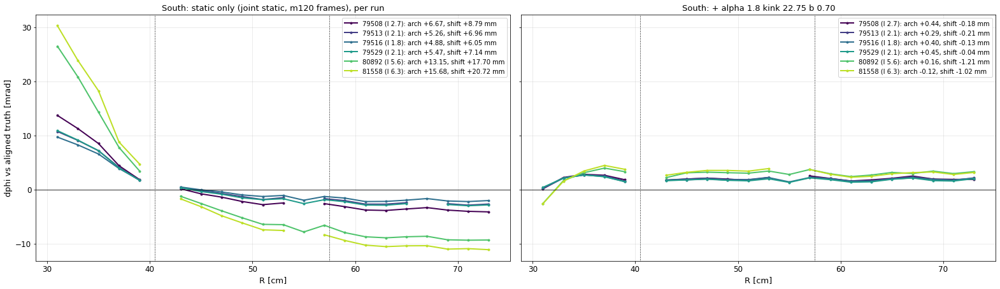

In [2]:
show(q.fig_abs_profiles(0, 'a1p8_r22p75_w2_o0', q.b_795(0, 'a1p8_r22p75_w2_o0') / 1000))

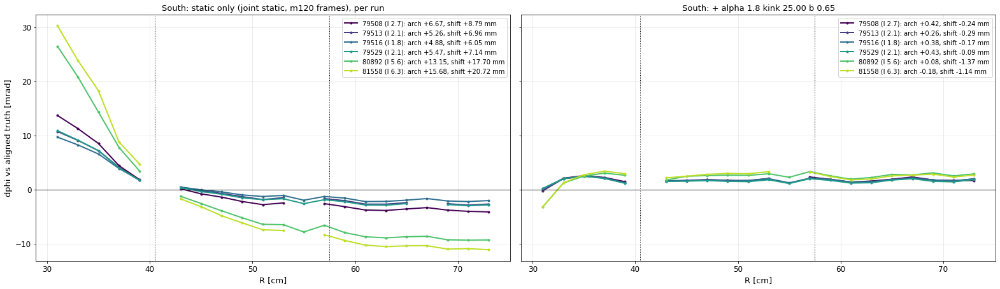

In [3]:
show(q.fig_abs_profiles(0, 'a1p8_r25p00_w2_o0', q.b_795(0, 'a1p8_r25p00_w2_o0') / 1000))

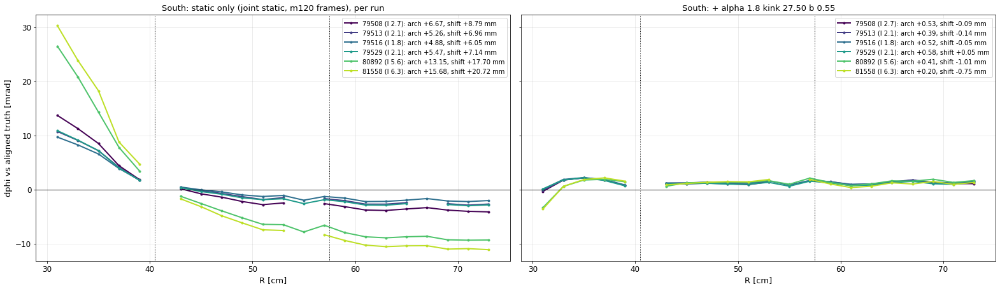

In [4]:
show(q.fig_abs_profiles(0, 'a1p8_r27p50_w2_o0', q.b_795(0, 'a1p8_r27p50_w2_o0') / 1000))

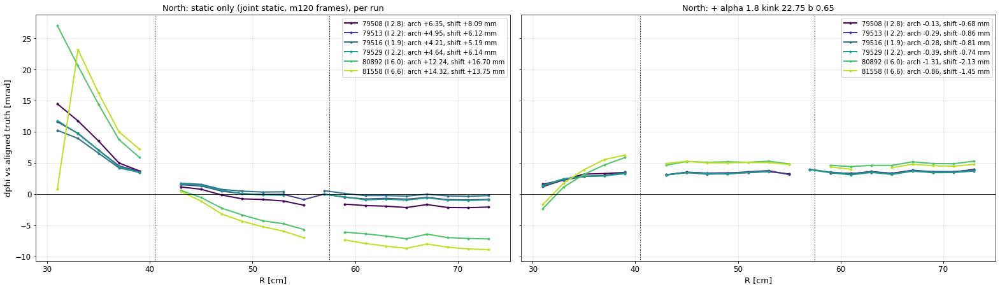

In [5]:
show(q.fig_abs_profiles(1, 'a1p8_r22p75_w2_o0', q.b_795(1, 'a1p8_r22p75_w2_o0') / 1000))

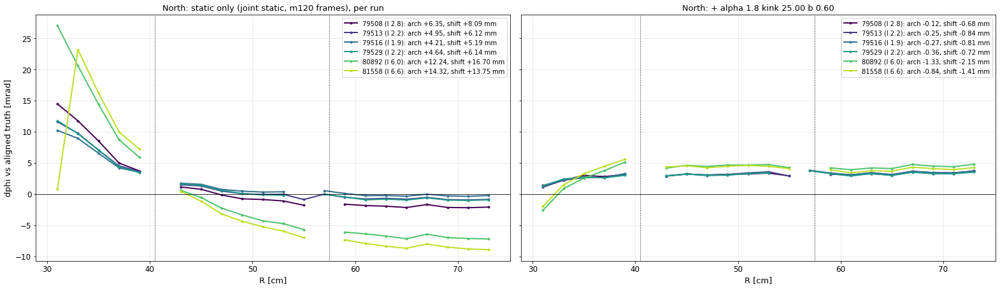

In [6]:
show(q.fig_abs_profiles(1, 'a1p8_r25p00_w2_o0', q.b_795(1, 'a1p8_r25p00_w2_o0') / 1000))

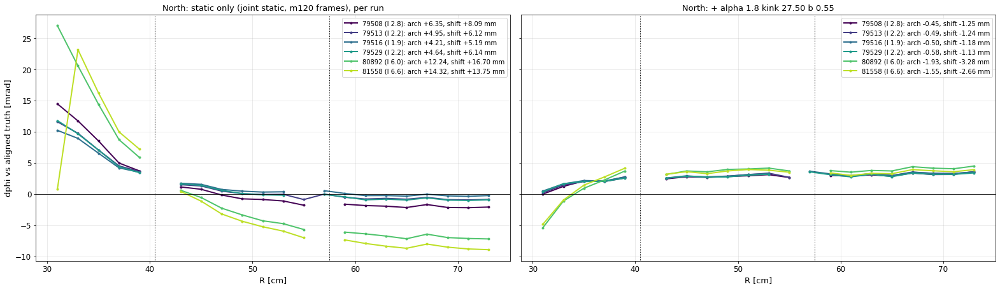

In [7]:
show(q.fig_abs_profiles(1, 'a1p8_r27p50_w2_o0', q.b_795(1, 'a1p8_r27p50_w2_o0') / 1000))

### 1b. The current CDB per run (for reference)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:330: RuntimeWarning: Mean of empty slice
  _DP[k] = np.nanmean(P, axis=0) if P else np.full(len(ta.PRC), np.nan)


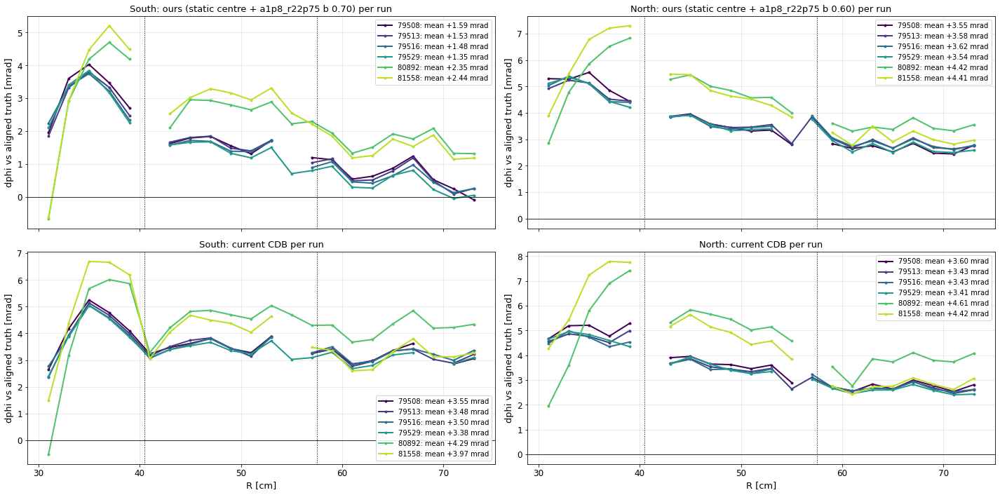

In [8]:
show(v.fig_runs_dphi())

## 2. Run − run differences, raw [mrad]
All 15 pairs of the six beam runs. Black: static only = the measured change (space charge, + static change in North
across periods); red: what the CDB leaves; dashed: what the best maps (α 1.6 kink 25 / 26.25, α 1.7 kink 25) and α 1.8 kink 22.75 (the CDB shape) leave, each at its 795xx b. A flat black curve
means no change; an arch in black that the maps remove is space charge; an arch that no map removes and that does
not scale with ΔI is not space charge.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:333: RuntimeWarning: Mean of empty slice
  _c[key] = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


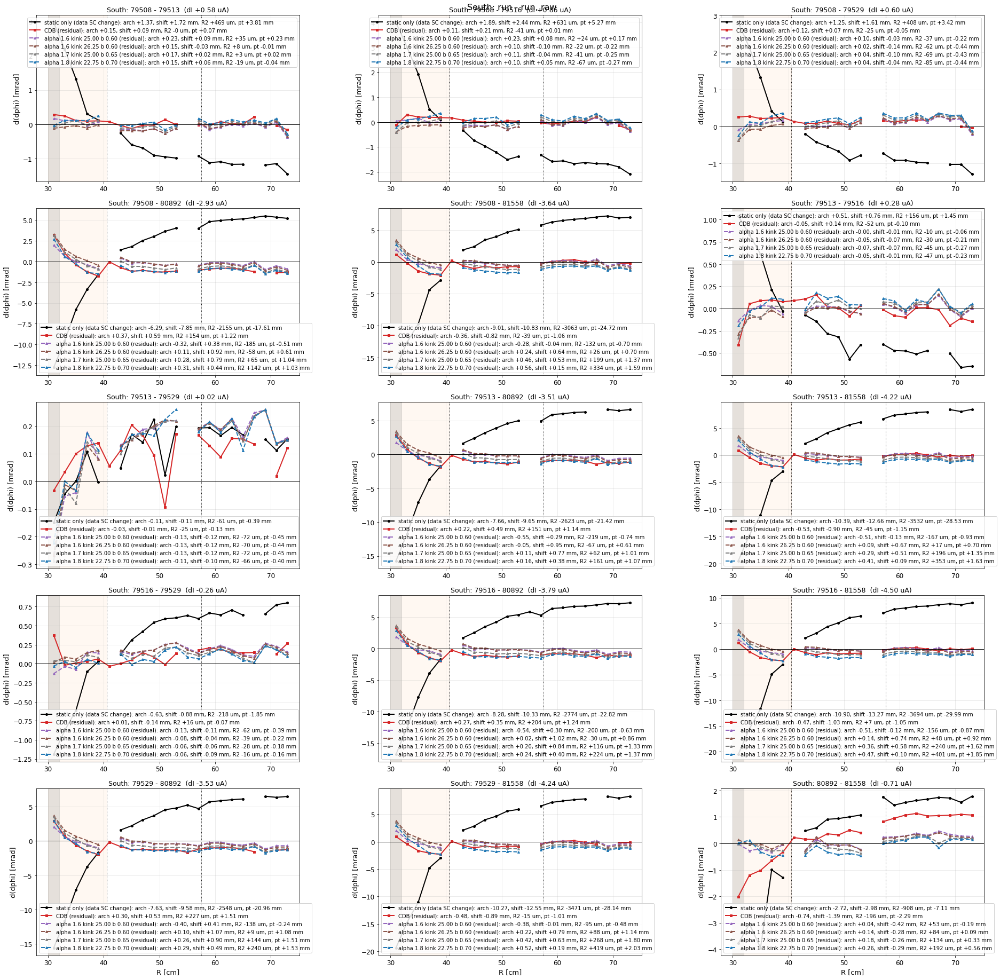

In [9]:
show(q.fig_run_diffs(0, CF[0], title='South: run - run, raw'))

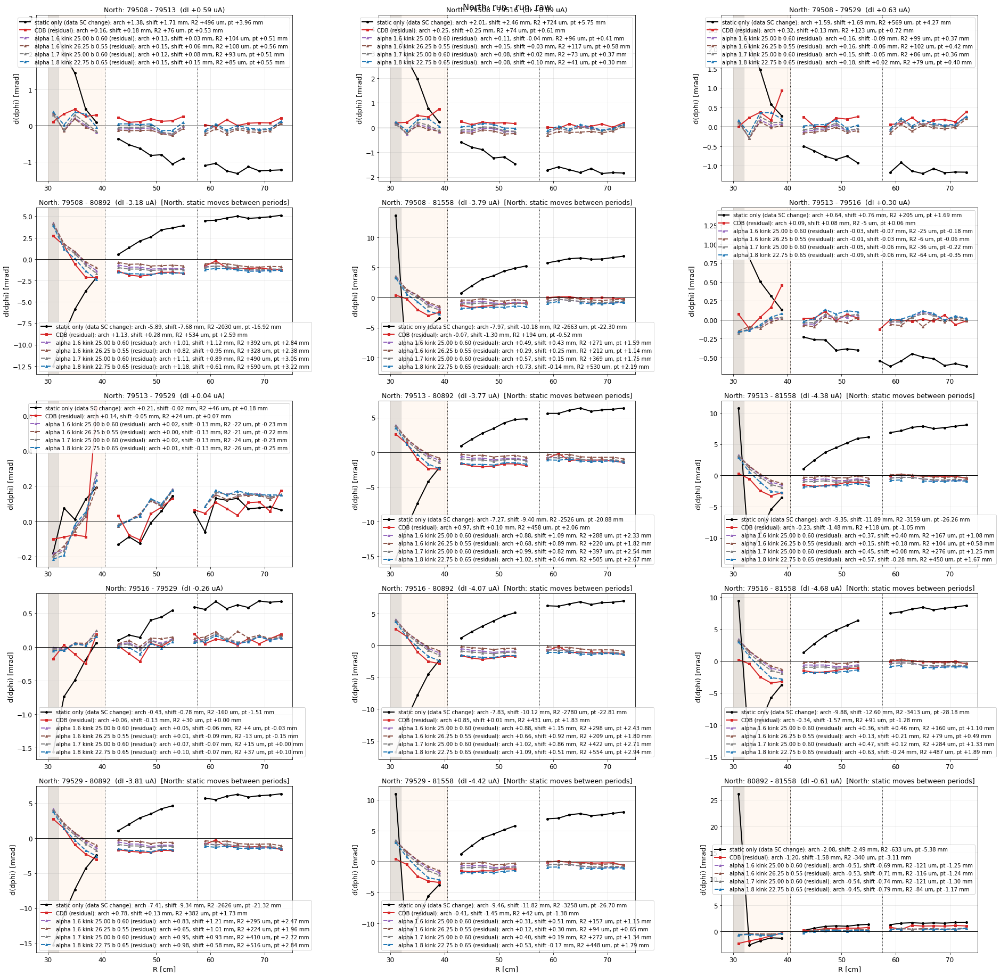

In [10]:
show(q.fig_run_diffs(1, CF[1], title='North: run - run, raw'))

## 3. Run − run differences per µA (pairs with |ΔI| > 0.2 µA)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


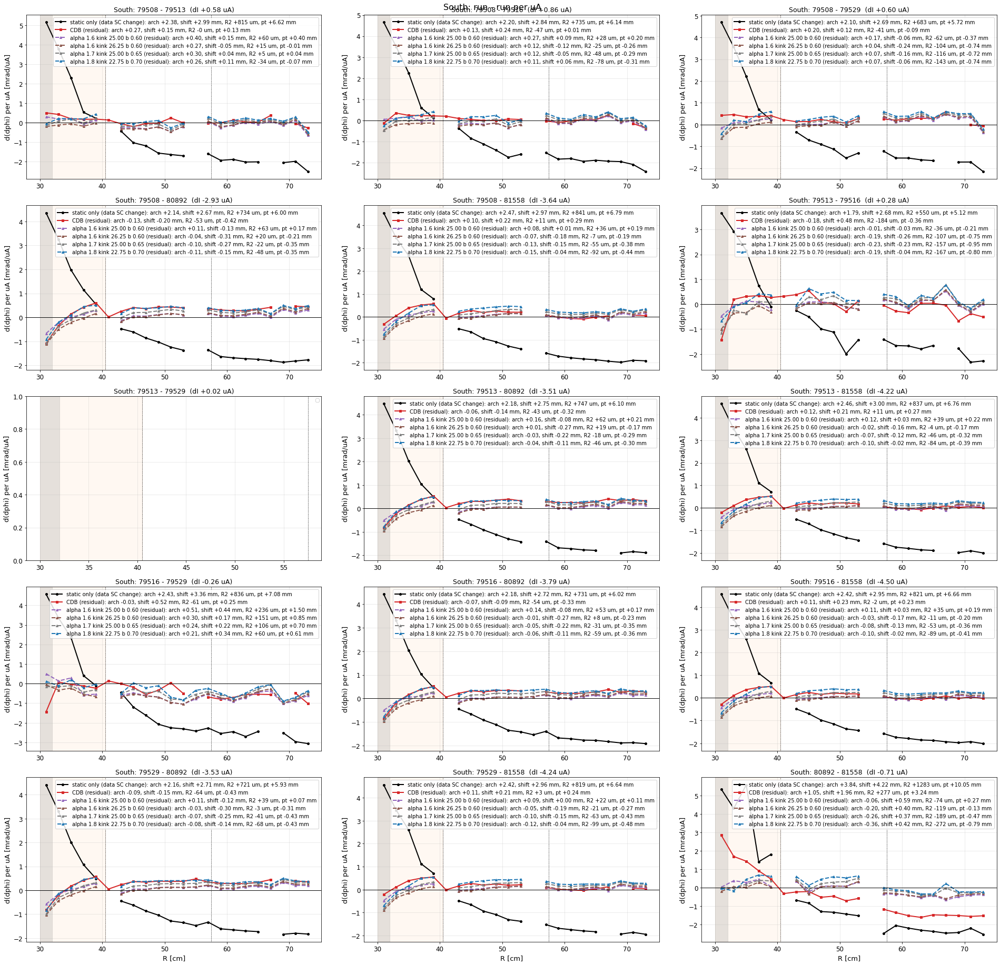

In [11]:
show(q.fig_run_diffs(0, CF[0], per_uA=True, title='South: run - run per uA'))

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


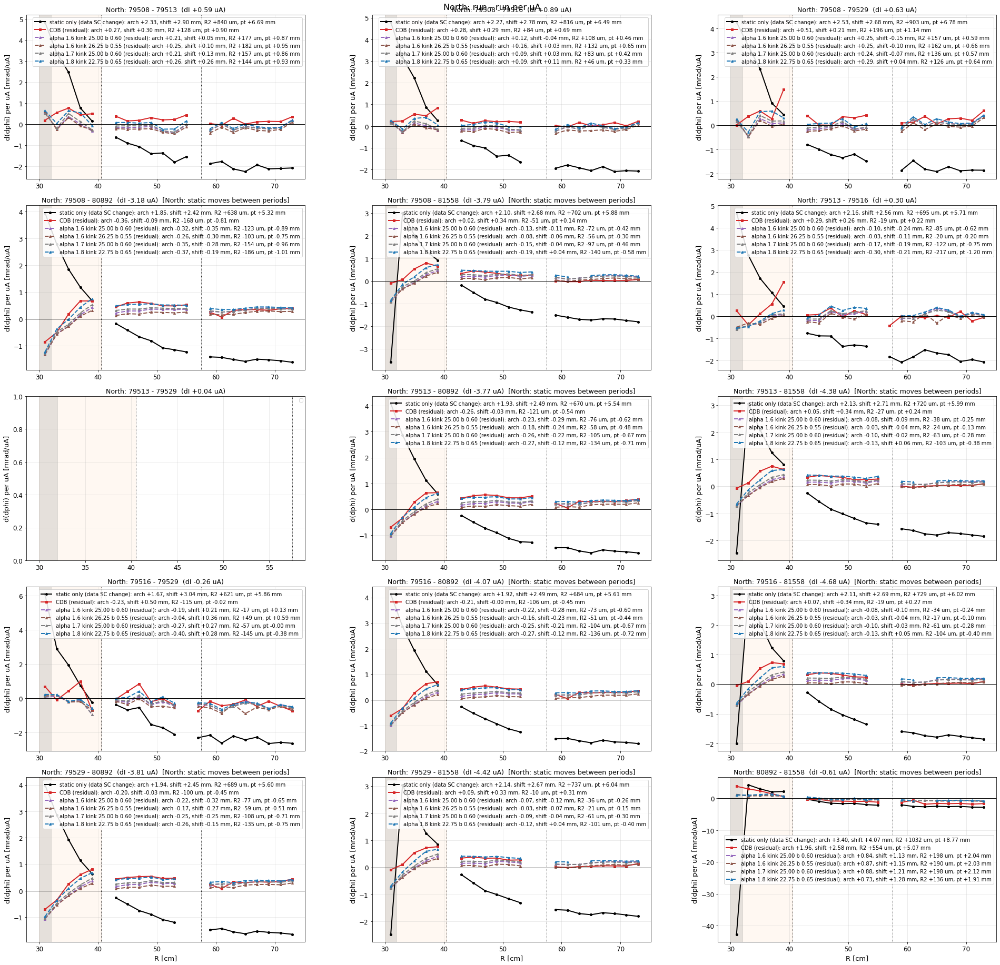

In [12]:
show(q.fig_run_diffs(1, CF[1], per_uA=True, title='North: run - run per uA'))

## 4. Key pairs in four φ bins (raw)
79508 − 79516 (low luminosity, ΔI ≈ 0.9 µA), 80892 − 79516 and 81558 − 79516 (high − low), 81558 − 80892 (two
high-luminosity runs, ΔI ≈ 0.7 µA). If the R1 arch is a local (sector / φ) feature it shows up in one φ bin only.

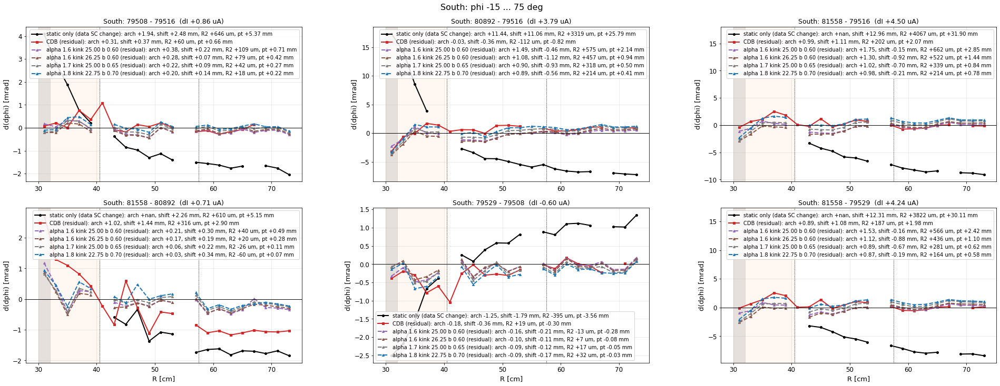

In [13]:
show(q.fig_run_diffs(0, CF[0], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(-15, 75), title='South: phi -15 ... 75 deg'))

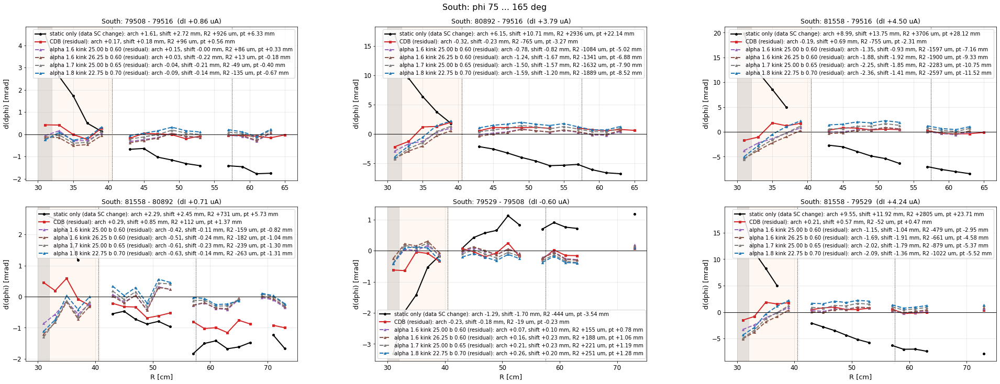

In [14]:
show(q.fig_run_diffs(0, CF[0], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(75, 165), title='South: phi 75 ... 165 deg'))

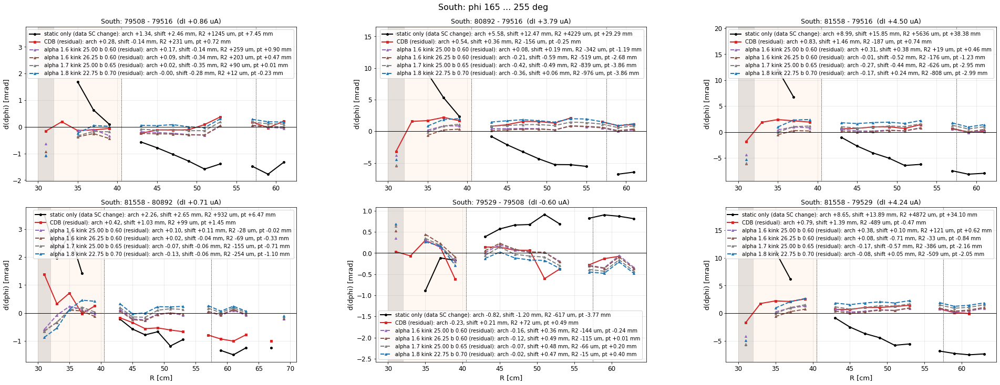

In [15]:
show(q.fig_run_diffs(0, CF[0], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(165, 255), title='South: phi 165 ... 255 deg'))

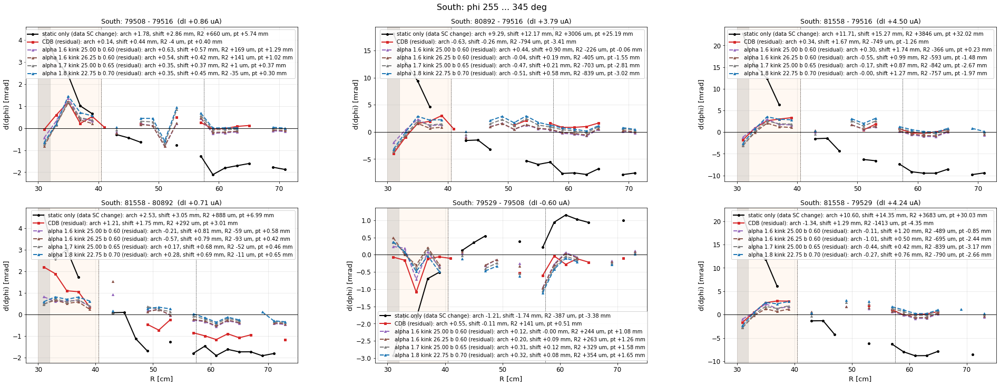

In [16]:
show(q.fig_run_diffs(0, CF[0], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(255, 345), title='South: phi 255 ... 345 deg'))

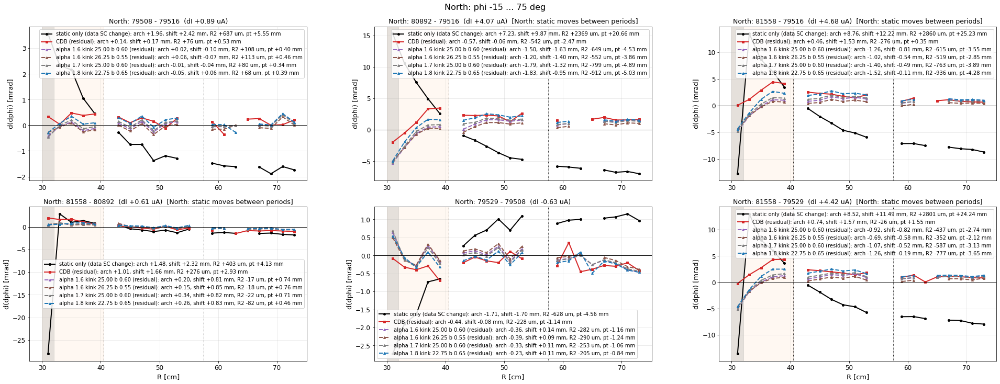

In [17]:
show(q.fig_run_diffs(1, CF[1], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(-15, 75), title='North: phi -15 ... 75 deg'))

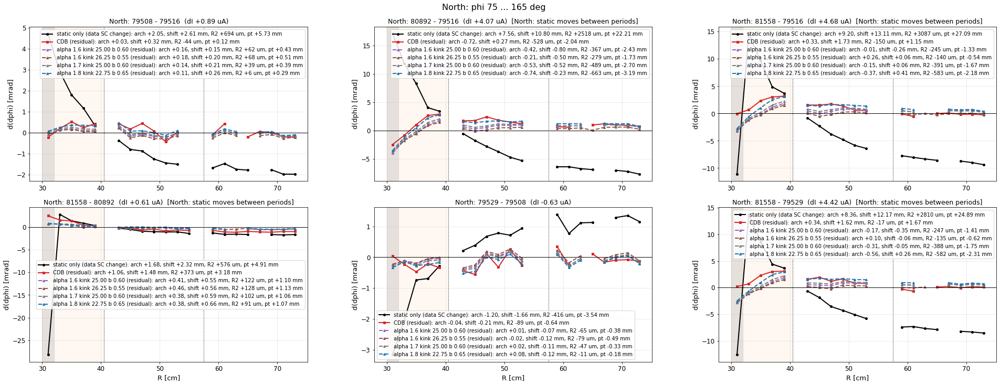

In [18]:
show(q.fig_run_diffs(1, CF[1], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(75, 165), title='North: phi 75 ... 165 deg'))

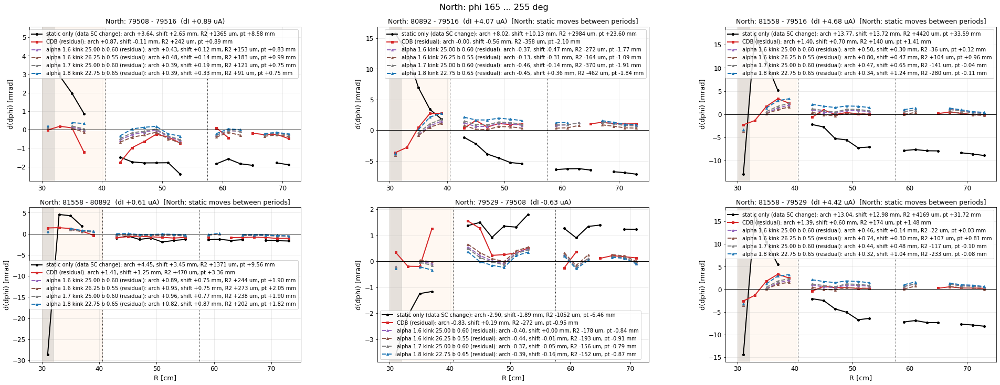

In [19]:
show(q.fig_run_diffs(1, CF[1], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(165, 255), title='North: phi 165 ... 255 deg'))

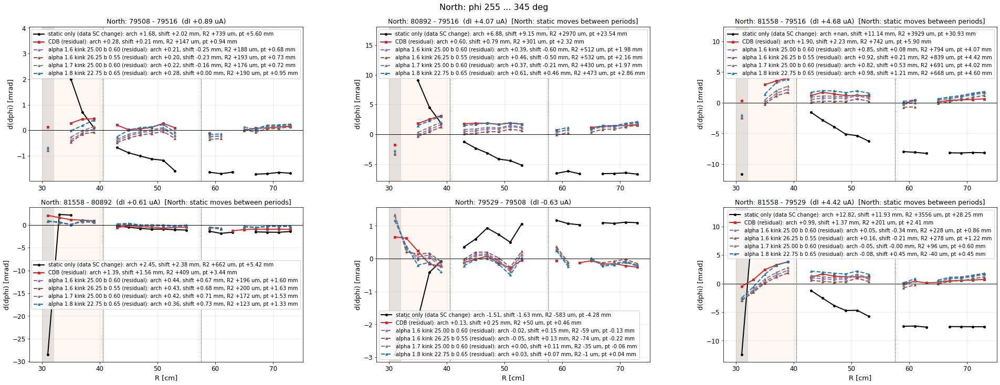

In [20]:
show(q.fig_run_diffs(1, CF[1], pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(255, 345), title='North: phi 255 ... 345 deg'))

## 5. Inside each run: first block − last block (same fill, same static: the cleanest current change)

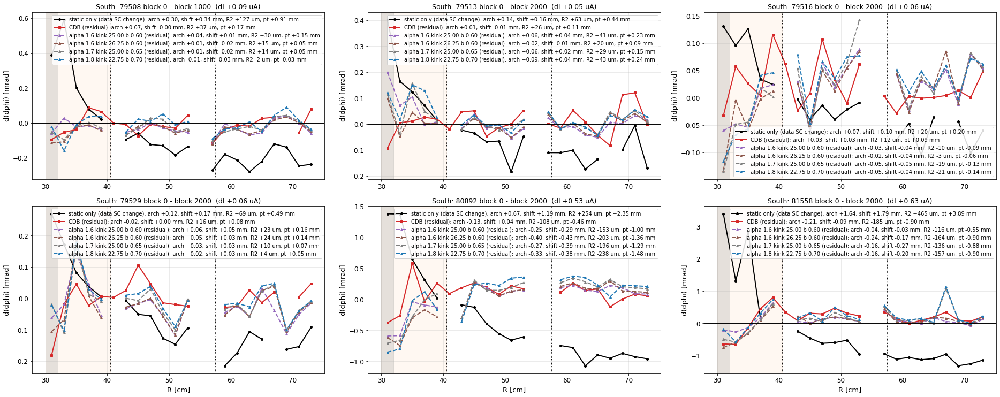

In [21]:
show(q.fig_block_diffs(0, CF[0]))

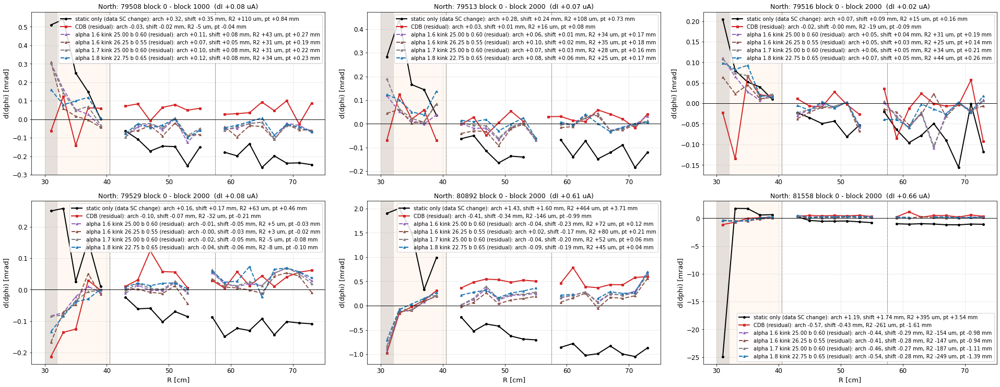

In [22]:
show(q.fig_block_diffs(1, CF[1]))

## 6. Every block − 79516, coloured by the current: does the R1 arch grow with I?

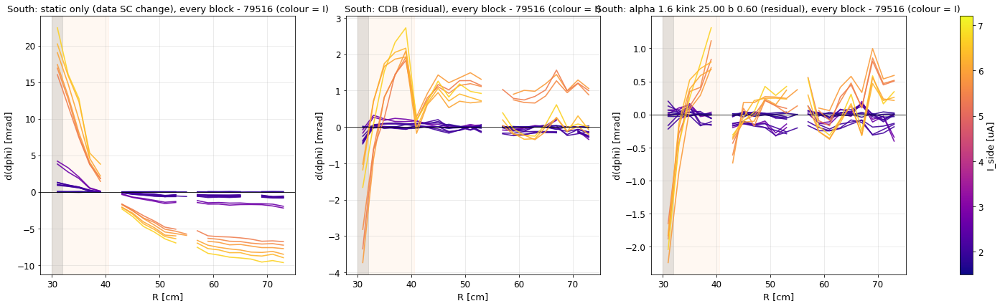

In [23]:
show(q.fig_diff_vs_I(0, CF[0][:3]))

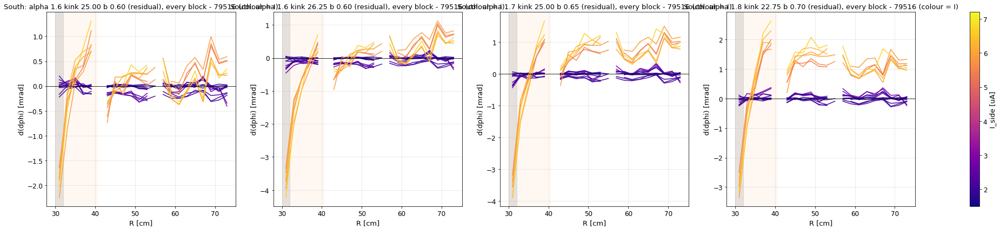

In [24]:
show(q.fig_diff_vs_I(0, CF[0][2:]))

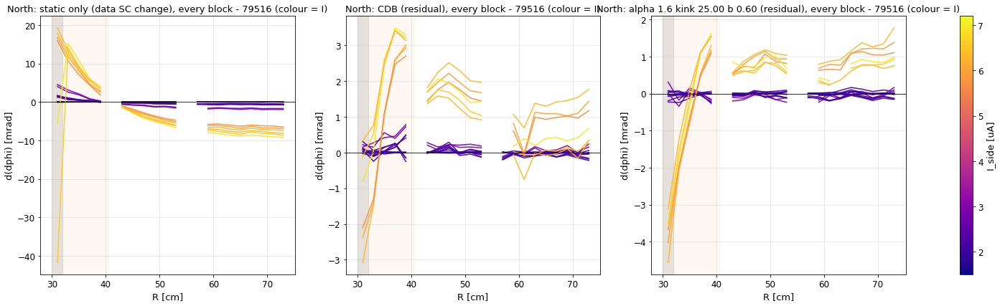

In [25]:
show(q.fig_diff_vs_I(1, CF[1][:3]))

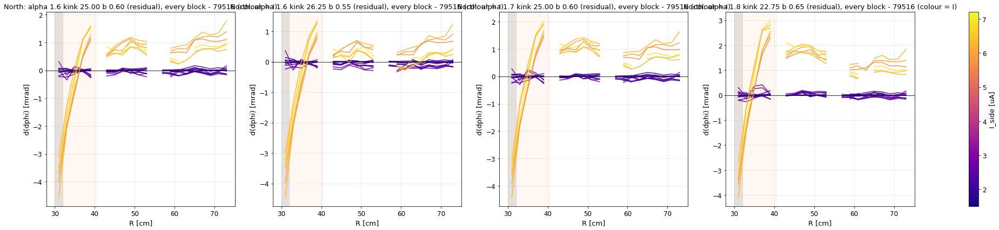

In [26]:
show(q.fig_diff_vs_I(1, CF[1][2:]))

## 7. Absolute quantities vs I_GEM per block
Per block: R1 arch, sideways shift, R², pointing vs I. Line: fit to the 795xx blocks (o), extrapolated to the
high-luminosity blocks ([]). Intercept at I = 0 = the static part; slope = what the space charge (or the map's error)
adds per µA. Static only, and each α 1.8 kink at its 795xx b.

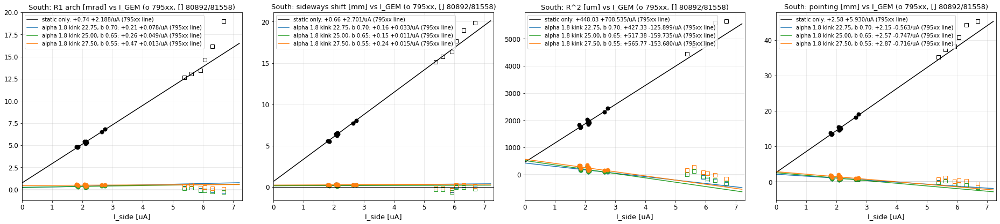

In [27]:
show(q.fig_arch_vs_I(0))

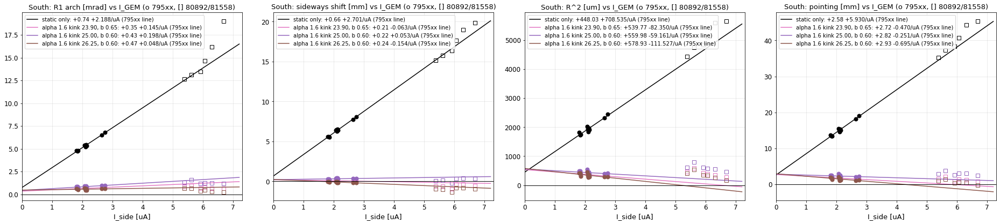

In [28]:
show(q.fig_arch_vs_I(0, maps=(('a1p6_r23p9m_w2_o0', None), ('a1p6_r25p00_w2_o0', None), ('a1p6_r26p25m_w2_o0', None))))

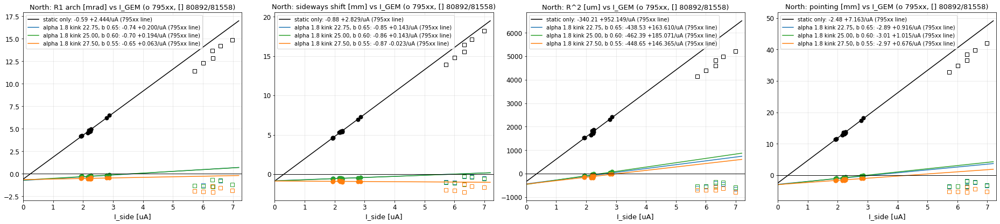

In [29]:
show(q.fig_arch_vs_I(1))

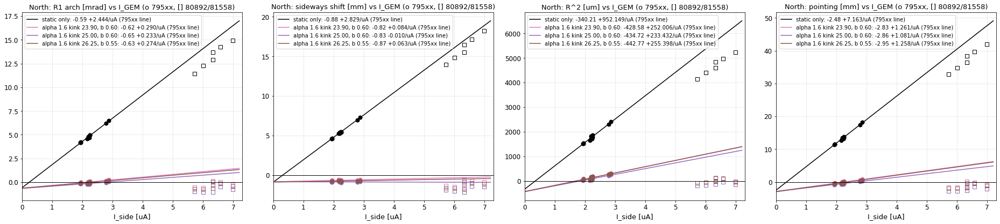

In [30]:
show(q.fig_arch_vs_I(1, maps=(('a1p6_r23p9m_w2_o0', None), ('a1p6_r25p00_w2_o0', None), ('a1p6_r26p25m_w2_o0', None))))

## 8. Which map reproduces which change: pairs of block sets, each map at its own best b
Pairs: 795xx 3 highest − 3 lowest blocks; 80892 block 0 − 2; 81558 block 0 − 2; 81558 − 79516; 80892 − 79516 (the last
two clean in South only). For each map, b is fitted per pair (residual rms per µA about its mean, rotation free).
### 8a. Tables: data per µA and every map's residual per µA (sorted by residual rms)

In [31]:
T0 = q.print_pair_table(0)


South | 795xx: 3 highest - 3 lowest blocks (dI 0.68 uA) - per uA
                                   b   rms |      rot    shift       R2 pointing     arch    step1    step2
  data                                     |   -6.660   +2.868   +692.1   +5.975   +2.104   +0.374   -0.149
  alpha 1.8 kink 27.50          0.56 0.133 |   -0.127   -0.001    -83.4   -0.400   +0.018   -0.043   -0.199   (residual)
  alpha 1.8 kink 26.25          0.60 0.134 |   -0.068   +0.018    -87.8   -0.401   +0.042   -0.115   -0.199   (residual)
  alpha 1.8 kink 25.00          0.64 0.148 |   -0.058   +0.061    -72.3   -0.286   +0.097   -0.173   -0.196   (residual)
  alpha 1.7 kink 25.00          0.63 0.148 |   -0.039   +0.025    -33.8   -0.148   +0.140   -0.131   -0.201   (residual)
  alpha 1.6 kink 26.25          0.58 0.150 |   -0.043   -0.042     -4.7   -0.085   +0.145   -0.037   -0.215   (residual)
  alpha 1.6 kink 23.90          0.64 0.152 |   -0.007   +0.001     +6.1   +0.009   +0.203   -0.138   -0.214   (re

In [32]:
T1 = q.print_pair_table(1)


North | 795xx: 3 highest - 3 lowest blocks (dI 0.70 uA) - per uA
                                   b   rms |      rot    shift       R2 pointing     arch    step1    step2
  data                                     |   -6.314   +2.735   +677.9   +5.781   +2.222   -0.020   -0.658
  alpha 1.8 kink 27.50          0.54 0.095 |   -0.150   -0.003    +22.1   +0.114   -0.010   -0.084   -0.001   (residual)
  alpha 1.6 kink 26.25          0.56 0.097 |   -0.166   +0.000   +110.2   +0.519   +0.144   -0.082   -0.038   (residual)
  alpha 1.6 kink 23.90          0.61 0.104 |   -0.082   +0.009   +102.6   +0.490   +0.150   -0.062   +0.001   (residual)
  alpha 1.8 kink 26.25          0.57 0.106 |   -0.125   +0.019    +22.1   +0.134   +0.008   -0.064   -0.013   (residual)
  alpha 1.6 kink 25.00          0.59 0.108 |   -0.060   -0.013   +101.0   +0.460   +0.139   -0.054   +0.003   (residual)
  alpha 1.7 kink 25.00          0.60 0.108 |   -0.110   +0.029    +66.1   +0.344   +0.092   -0.045   +0.022   (re

### 8b. Data vs prediction per pair (four representative maps), and the residual

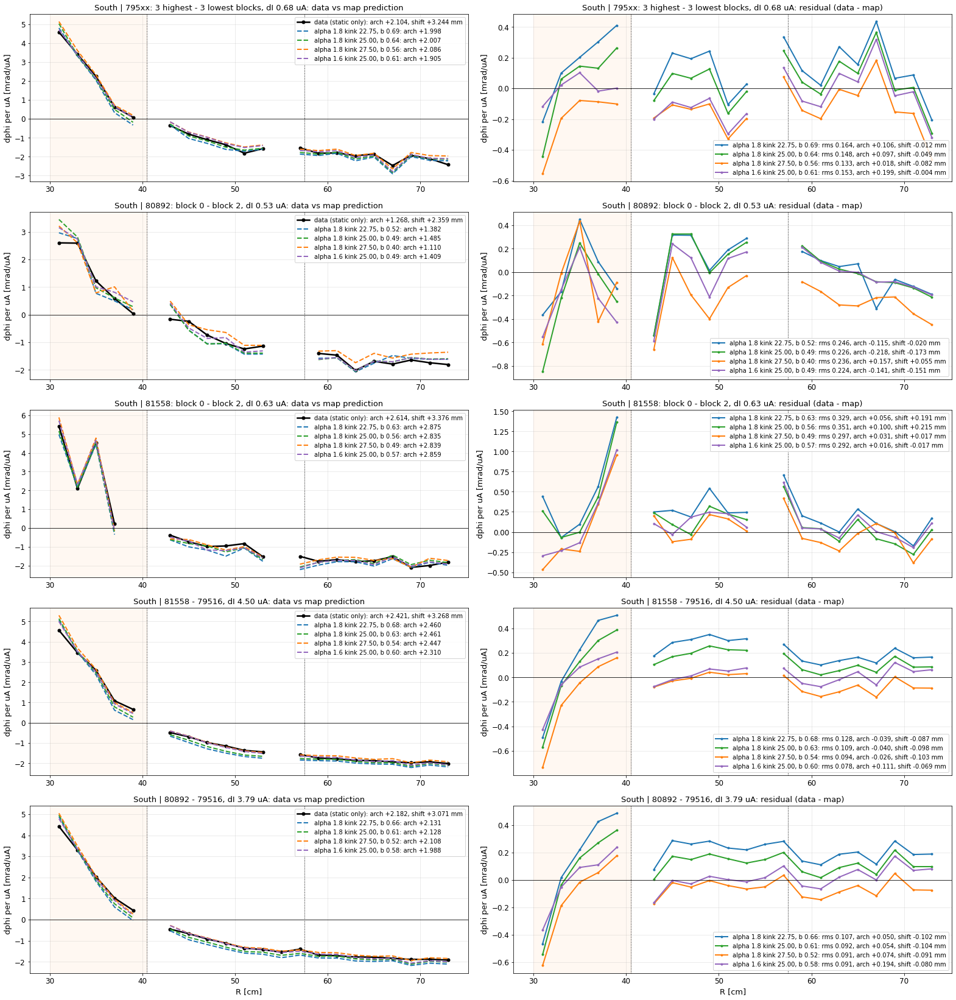

In [33]:
show(q.fig_pairs(0))

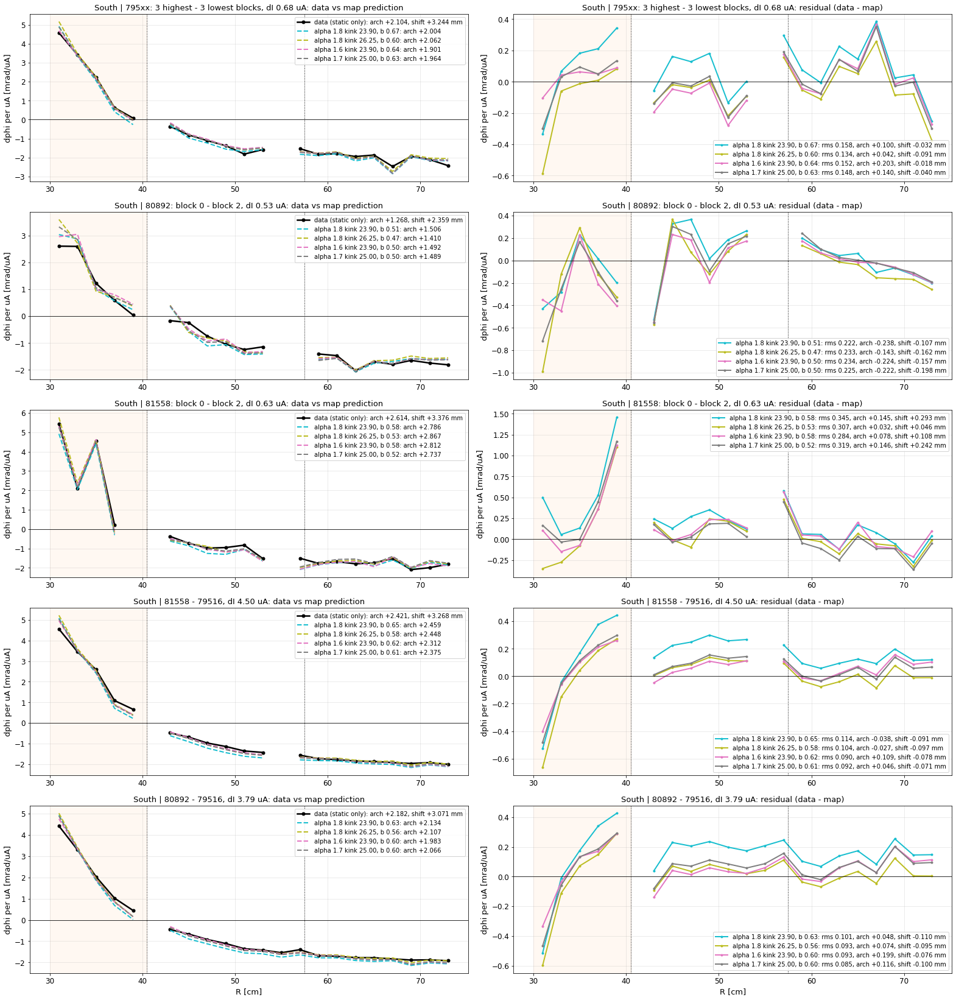

In [34]:
show(q.fig_pairs(0, maps=('a1p8_r23p9m_w2_o0', 'a1p8_r26p25m_w2_o0', 'a1p6_r23p9m_w2_o0', 'a1p7m_r25p00_w2_o0')))

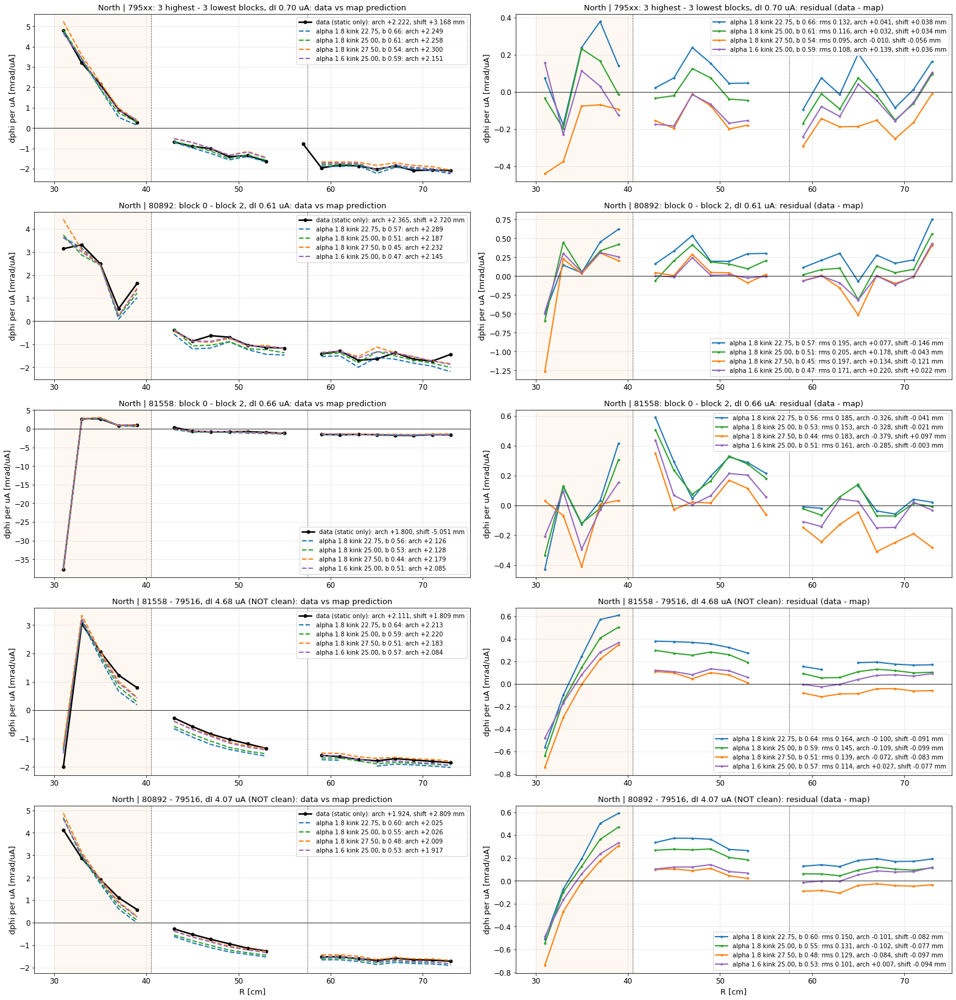

In [35]:
show(q.fig_pairs(1))

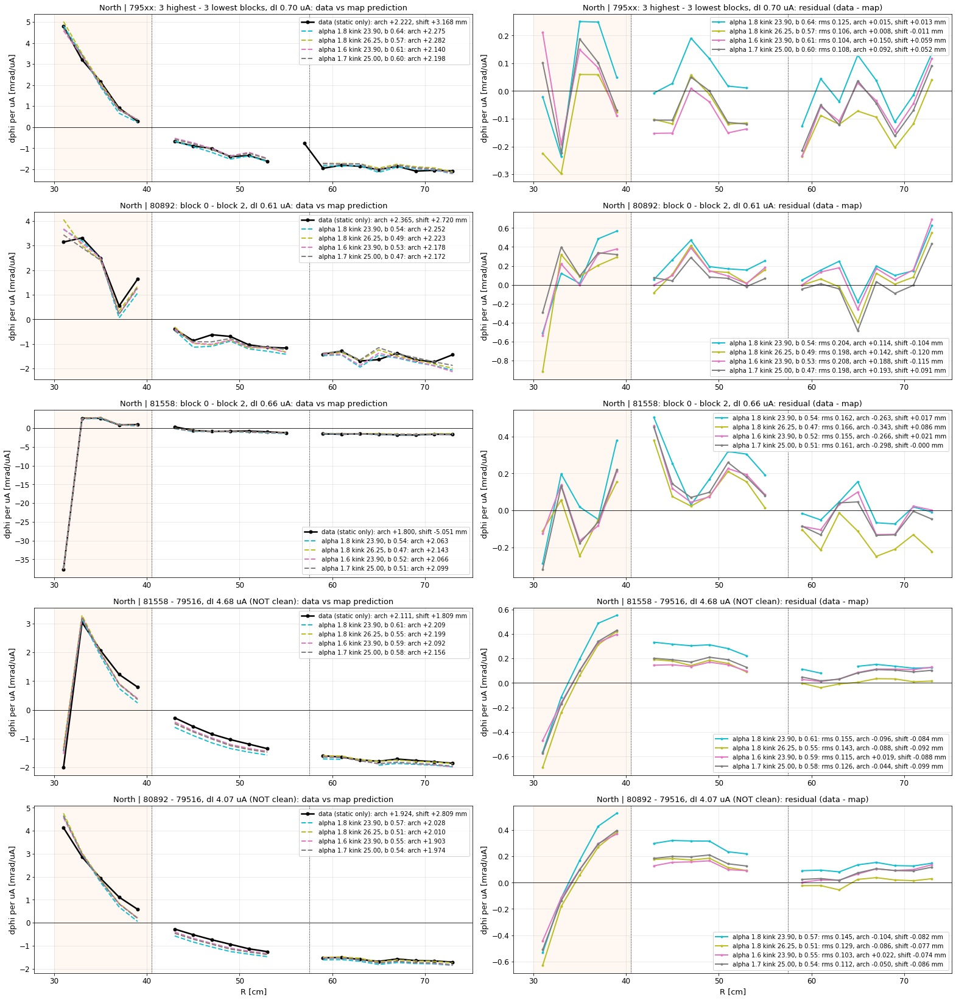

In [36]:
show(q.fig_pairs(1, maps=('a1p8_r23p9m_w2_o0', 'a1p8_r26p25m_w2_o0', 'a1p6_r23p9m_w2_o0', 'a1p7m_r25p00_w2_o0')))

### 8c. Every decomposed quantity per µA: data (black) vs each map's prediction

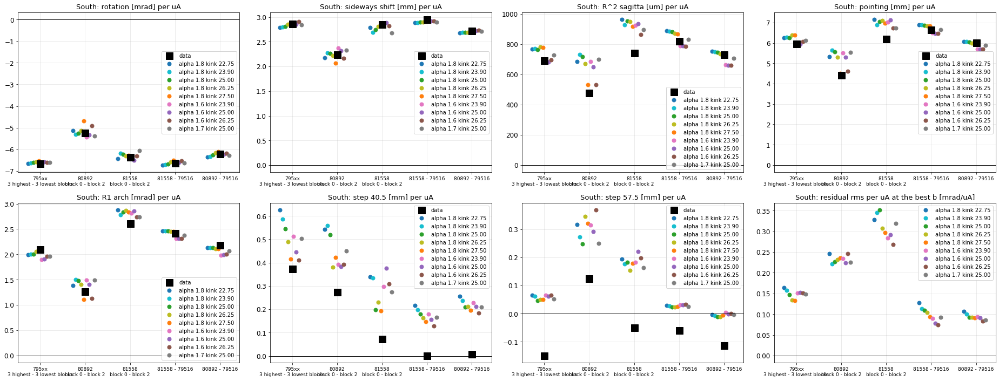

In [37]:
show(q.fig_pair_metrics(0))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:65: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0), I


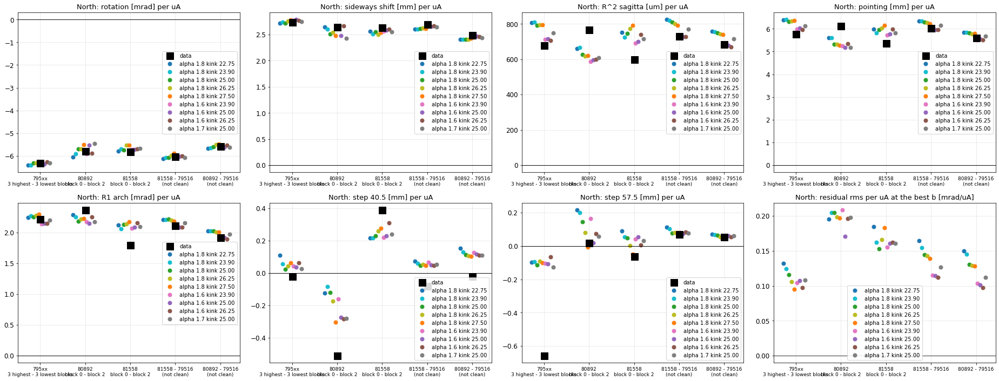

In [38]:
show(q.fig_pair_metrics(1))

### 8d. Kink scan: residual rms, best b, residual arch and shift vs the kink, per pair

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:65: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0), I


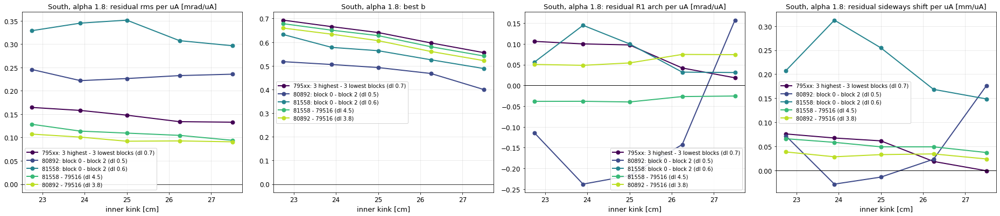

In [39]:
show(q.fig_kink_scan(0, '1p8'))

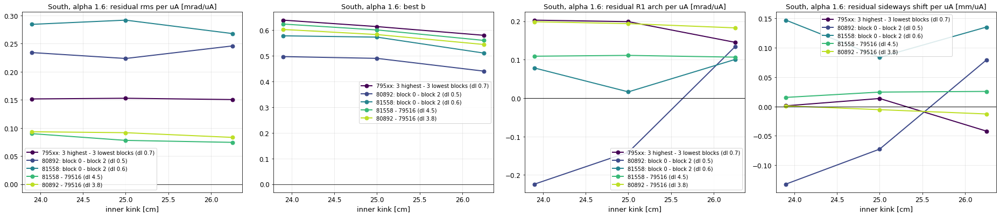

In [40]:
show(q.fig_kink_scan(0, '1p6'))

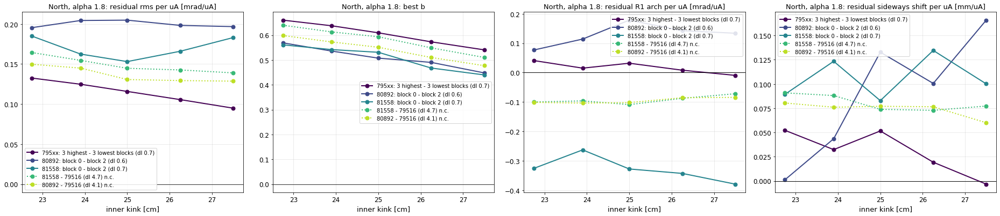

In [41]:
show(q.fig_kink_scan(1, '1p8'))

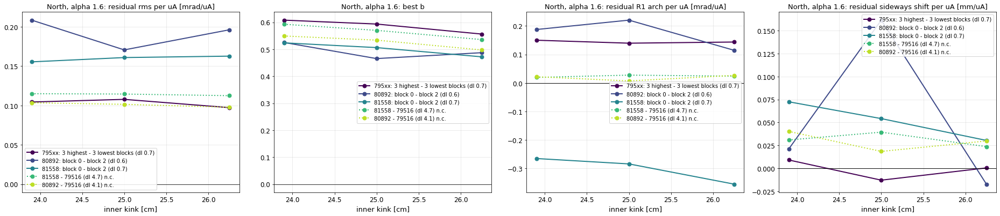

In [42]:
show(q.fig_kink_scan(1, '1p6'))

## 9. What limits the space-charge correction?
### 9a. Which GEM current
The scans scale keff with the **per-side median current over all modules** (CDB GEM payload "SOUTH" / "NORTH"); the
payload has only R1 and that median (no separate R2 / R3). R1 / median is not constant: 795xx 1.61–1.64 (S) /
1.45–1.51 (N), 80892 1.755 / 1.575, 81558 1.647 / 1.490.

Test: the static-only profiles of all blocks fitted as P0(R) + I·P1(R) with *any* shape P1 – the per-block residual is
how well a current describes the change. Left: vs the R1 weight of a mixed current.

79508: SR1 4.31  SOUTH 2.65  R1/med 1.626  |  NR1 4.22  NORTH 2.79  R1/med 1.510
79513: SR1 3.36  SOUTH 2.09  R1/med 1.608  |  NR1 3.20  NORTH 2.22  R1/med 1.445
79516: SR1 2.93  SOUTH 1.83  R1/med 1.606  |  NR1 2.78  NORTH 1.92  R1/med 1.448
79529: SR1 3.39  SOUTH 2.07  R1/med 1.637  |  NR1 3.17  NORTH 2.18  R1/med 1.456
80892: SR1 9.65  SOUTH 5.50  R1/med 1.755  |  NR1 9.19  NORTH 5.83  R1/med 1.575
81558: SR1 9.96  SOUTH 6.04  R1/med 1.647  |  NR1 9.45  NORTH 6.34  R1/med 1.490
South median, linear 0.238 | median, quadratic 0.201 | R1, linear 0.400 | R1, quadratic 0.384 | best R1 weight -0.50: 0.200 mrad
North median, linear 0.111 | median, quadratic 0.079 | R1, linear 0.109 | R1, quadratic 0.085 | best R1 weight +0.55: 0.105 mrad


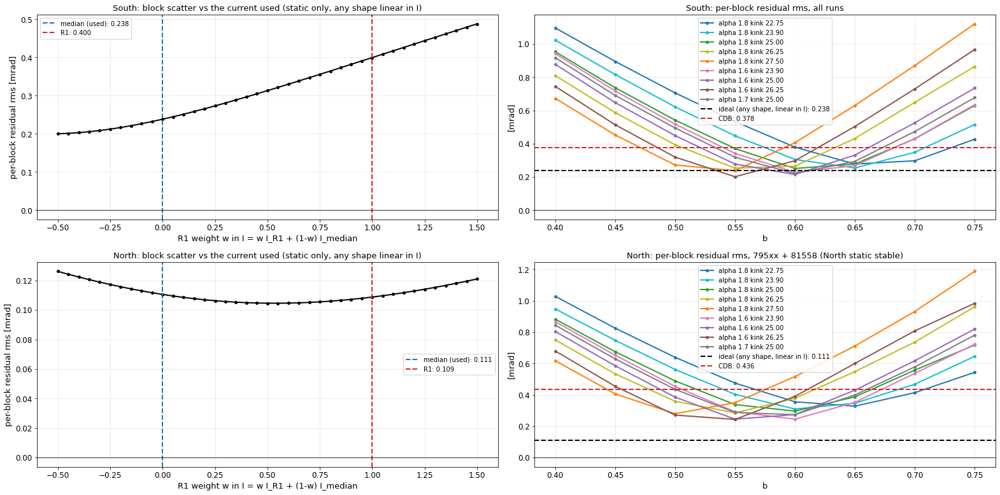

In [43]:
for r, sr1, sm, rs, nr1, nm, rn in q.run_current_table():
    print(f"{r}: SR1 {sr1:.2f}  SOUTH {sm:.2f}  R1/med {rs:.3f}  |  NR1 {nr1:.2f}  NORTH {nm:.2f}  R1/med {rn:.3f}")
for s in (0, 1):
    rows, ws, rr = q.current_test(s)
    print(c.SIDES[s], ' | '.join(f'{k} {x:.3f}' for k, x in rows.items()), f'| best R1 weight {ws[int(np.argmin(rr))]:+.2f}: {rr.min():.3f} mrad')
show(q.fig_limits())

- **The median current is right; R1 is clearly worse** (South 0.24 vs 0.40 mrad, North 0.11 vs 0.11–0.30). The best mix
  wants *less* R1 than the median: R1 is not a better proxy (80892 has high R1 / median with no matching extra charge).
- Quadratic in I helps a little (South 0.24 → 0.20, North 0.11 → 0.08): the response grows slightly less than linearly
  (the "b 12 % lower at high luminosity").

### 9b. How close are the maps to the best possible
Right panels: per-block residual rms with each map at each b, only a rotation per µA free, vs the ideal (static only
with any radial shape linear in I) and the CDB. Best map: South α 1.6 kink 26.25 b 0.55 → 0.20 mrad (ideal 0.24 linear,
0.13 with the map's own non-linearity; CDB 0.38); North 0.24 (ideal 0.10 – optimistic: with only two current levels a
North static change between the periods looks like a space-charge shape; CDB 0.44). Two maps with free weights gain only
0.01–0.04 mrad/µA, with unphysical negative weights.

**Limits**: (1) two current levels only (≈ 2 and 6 µA): a static change between the periods is indistinguishable from a
space-charge shape, and inside a run ΔI ≈ 0.6 µA is too small a lever; (2) the remaining shape is inside R1 (map
slightly too strong at 31–35 cm, too weak at 37–39 cm, ≈ 0.1 mrad/µA) – the kink cannot change it (it acts below
30 cm): it needs a different charge distribution inside R1 itself; (3) the 30–32 cm bin at high current.
**Decision**: fix the space charge (South α 1.7 kink 25 b 0.60, North α 1.6 kink 25 b 0.55, keff = b × I_median) and
move to the static (CM_laser_static_v7.ipynb).